# 4. Effective parameters and tunnelling amplitudes

**Question:** how do the laser-amplitude ratio and Bessel dressing change
the effective interaction and exchange magnitudes? Source: thesis Sec. 4,
especially Eqs. (66)-(67), (75); original `amplitudes_vs_muU_thesis.py`
and `mu_vs_A_over_U.py`.

**Model scope:** this notebook reproduces the archived analytic parameter
family. It is evaluated before the separately imposed $|11\rangle$ diagonal
compensation. Its $\mu_{\rm eff},U_{\rm eff}$ must not be substituted into
the compensated chain as if every diagonal term were thereby matched.

## Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

## 4.1 Definitions with their dimensions

The $C_{ab}$ interaction shifts and the real laser-coupling
amplitudes $\Omega_a,\Omega_b$ use the normalization in Notebook 1.
The drive has modulation amplitude $A$, rate $\omega'$, and dimensionless
index $\kappa=A/\omega'$. Its common detuning offset is
$\widetilde\nu=2C_{11}-C_{02}-m\omega'$ for integer resonance order $m$.
$J_\ell$ denotes the Bessel function of the first kind. In code, each
sideband sum runs from $-\ell_{\max}$ to $+\ell_{\max}$; convergence must
be checked by increasing that cutoff.

Define the inverse-rate quantities
$$D_1=(C_{01}-2C_{00})^{-1},\quad D_2=(2C_{11}-C_{01})^{-1},\quad
  D_3=(C_{12}-C_{02})^{-1},$$
$$a=3D_1-D_2,\qquad b=4D_1+D_3-2D_2.$$
Define the dimensionless intensity ratio
$r=\Omega_b^2/\Omega_a^2\geq0$ with $\Omega_a\neq0$, and let
$$\Sigma(\kappa)=\sum_\ell\frac{J_\ell(\kappa)^2}
      {C_{02}-C_{01}+\widetilde\nu+\ell\omega'},\qquad x=r\Sigma(\kappa).$$
Both $x$ and $a,b$ have inverse-rate dimensions. To derive the
effective quantities, use three uncompensated bond diagonal rates:
$$\epsilon_{00}=-2\Omega_a^2D_1,\quad
 \epsilon_{01}=\Omega_a^2(D_1-D_2)-\Omega_b^2\Sigma,\quad
 \epsilon_{02}=\Omega_b^2\Sigma-\Omega_a^2D_3.$$
The source uses the **plus-cost** convention
$\mu_{\rm eff}=\epsilon_{01}-\epsilon_{00}$: positive $\mu_{\rm eff}$
means that adding the first occupation quantum costs energy. It would
correspond to the negative of a chemical potential written as $-\mu N$.
Subtract the diagonals explicitly:
$$\mu_{\rm eff}=\Omega_a^2(D_1-D_2)-\Omega_b^2\Sigma+2\Omega_a^2D_1
 =\Omega_a^2(3D_1-D_2)-\Omega_b^2\Sigma.$$
The second-addition excess is
$$U_{\rm eff}=\epsilon_{02}-2\epsilon_{01}+\epsilon_{00}$$
$$=\Omega_b^2\Sigma-\Omega_a^2D_3
 -2\Omega_a^2(D_1-D_2)+2\Omega_b^2\Sigma-2\Omega_a^2D_1$$
$$=\Omega_a^2(-4D_1+2D_2-D_3)+3\Omega_b^2\Sigma.$$
Substitute $\Omega_b^2=r\Omega_a^2$, $a=3D_1-D_2$,
$b=4D_1+D_3-2D_2$, and $x=r\Sigma$ to obtain
$$\mu_{\rm eff}=\Omega_a^2(a-x),\qquad
  U_{\rm eff}=\Omega_a^2(3x-b).$$
Each right-hand side has rate dimensions. Dividing cancels the common scale:
$$\frac{\mu_{\rm eff}}{U_{\rm eff}}
   =\frac{\Omega_a^2(a-x)}{\Omega_a^2(3x-b)}
   =\frac{a-x}{3x-b},\qquad 3x-b\neq0.$$
This is a ratio of rates, so it is dimensionless.

## 4.2 Magnitudes and why their signs are treated separately

Let
$$\Sigma_4=\sum_\ell J_\ell(\kappa)^2\left[
  \frac1{C_{12}-2C_{11}+\widetilde\nu+\ell\omega'}-
  \frac1{2C_{22}-C_{12}+\widetilde\nu+\ell\omega'}\right].$$
The four positive or zero magnitudes are
$$A_1=\Omega_a^2|D_1-D_2|,$$
$$A_2=A_3=\Omega_a^2\sqrt r\,|D_2-D_3|\,|J_m(\kappa)|,$$
$$A_4=\Omega_a^2r|\Sigma_4|.$$
Magnitudes have the same rate units as $U_{\rm eff}$. A ratio $A_i/U_{\rm eff}$
can be negative when $U_{\rm eff}<0$, even though $A_i\geq0$. Taking absolute
values here loses the hopping sign information; the Hamiltonian notebooks
therefore use the signed rates instead.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

here = Path.cwd().resolve()
roots = [p for p in (here, *here.parents) if (p / 'anyon_thesis').is_dir()]
if not roots:
    raise FileNotFoundError('Open this notebook from the cloned repository.')
ROOT = roots[0]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from anyon_thesis.models import (
    EffectiveParameters, effective_bond, effective_chain, occupation_basis,
    phase_pattern, basis_state, evolve_probabilities, parameter_curves,
    target_hamiltonian, lowest_levels, gap_grid,
)
SAVE_FIGURES = False  # Optional export; raw scripts/data are never overwritten.
STYLE = {'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False}
def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / 'notebook_outputs'
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f'{name}.png', dpi=160)
    display(fig)
    plt.close(fig)
np.set_printoptions(precision=6, suppress=True)

Matplotlib is building the font cache; this may take a moment.


In [2]:
r = np.linspace(0, 4, 401)
kappas = [0.8, 1.2, 2.0]
families = {k: parameter_curves(k, r) for k in kappas}
reference = parameter_curves(1.2, np.array([1.0]))
for name in ['mu', 'U', 'amplitudes', 'mu_over_U']:
    print(name, reference[name])
assert np.all(reference['amplitudes'] >= 0)
assert np.allclose(reference['amplitudes'][1], reference['amplitudes'][2])

mu [0.04345]
U [-0.047016]
amplitudes [[0.05   ]
 [0.01661]
 [0.01661]
 [0.01012]]
mu_over_U [-0.924143]


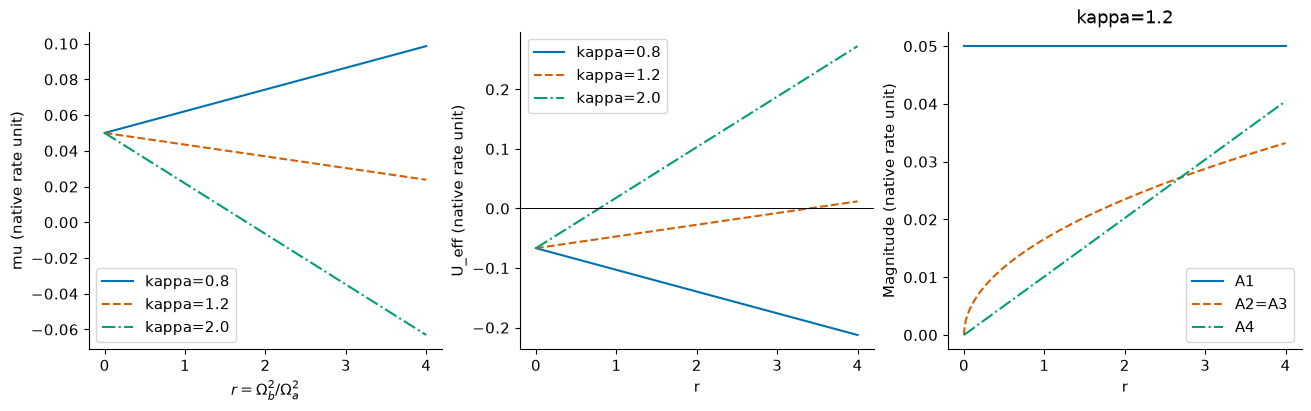

In [3]:
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
    colours, styles = ['#0072B2', '#D55E00', '#009E73'], ['-', '--', '-.']
    for k, colour, style in zip(kappas, colours, styles):
        result = families[k]
        axes[0].plot(r, result['mu'], color=colour, linestyle=style, label=f'kappa={k}')
        axes[1].plot(r, result['U'], color=colour, linestyle=style, label=f'kappa={k}')
    for i, colour, style, label in zip([0, 1, 3], colours, styles, ['A1', 'A2=A3', 'A4']):
        axes[2].plot(r, families[1.2]['amplitudes'][i], color=colour,
                     linestyle=style, label=label)
    axes[0].set(xlabel=r'$r=\Omega_b^2/\Omega_a^2$', ylabel='mu (native rate unit)')
    axes[1].set(xlabel='r', ylabel='U_eff (native rate unit)')
    axes[1].axhline(0, color='black', linewidth=0.7)
    axes[2].set(xlabel='r', ylabel='Magnitude (native rate unit)', title='kappa=1.2')
    for ax in axes:
        ax.legend()
    show_figure(fig, '04_parameters_and_amplitudes')

**Figure description:** the first two panels vary $r$ at each labelled
modulation index. The third compares magnitudes at a fixed modulation index.
Every line uses a distinct style as well as colour. The zero line marks
attraction versus repulsion in the effective-parameter formula family.

## 4.3 Poles and limiting cases

Provided $b\neq0$,
$$\left.\frac{\mu_{\rm eff}}{U_{\rm eff}}\right|_{x=0}=-\frac ab.$$
For large nonzero $x$, divide numerator and denominator by $x$:
$$\frac{a-x}{3x-b}=\frac{a/x-1}{3-b/x}
     \longrightarrow -\frac13.$$
This is a formal algebraic limit. Reaching arbitrarily large $r$ at fixed
$\Omega_a$ can violate the dispersive approximation, so the limit is not an
experimentally validated operating regime.

At $x=b/3$, $U_{\rm eff}=0$. If $a-b/3\neq0$ the ratio has a pole.
If $a=b/3$, the common zero instead cancels away from $x=b/3$, giving
$-1/3$, while the original $0/0$ ratio remains undefined at that point.
Whether the pole occurs for physical $r\geq0$ depends on the sign and possible
zero of $\Sigma$; $x$ is not an independently adjustable unrestricted input.

To plot the ratio without drawing a false line through its pole, split the
samples into constant-sign-$U_{\rm eff}$ branches. Never connect the two
branches with a line or replace the singular value by zero.

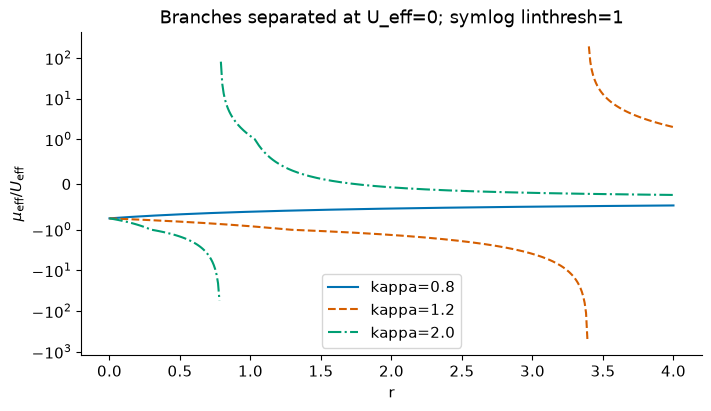

Formal large-x ratio: -0.3333333333240741 ; limit = -1/3


In [4]:
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
    for k, colour, style in zip(kappas, colours, styles):
        result = families[k]
        signs = np.sign(result['U'])
        splits = np.flatnonzero(np.diff(signs) != 0)+1
        for index, branch in enumerate(np.split(np.arange(len(r)), splits)):
            ax.plot(r[branch], result['mu_over_U'][branch], color=colour,
                    linestyle=style, label=f'kappa={k}' if index == 0 else None)
    ax.set_yscale('symlog', linthresh=1)
    ax.set(xlabel='r', ylabel=r'$\mu_{\rm eff}/U_{\rm eff}$',
           title='Branches separated at U_eff=0; symlog linthresh=1')
    ax.legend()
    show_figure(fig, '04_ratio_branches')
a, b = reference['a'], reference['b']
assert np.isclose((a-0)/(3*0-b), -a/b)
formal_x = 1e9
print('Formal large-x ratio:', (a-formal_x)/(3*formal_x-b), '; limit = -1/3')

## 4.4 Overall drive scaling

Scale both Rabi rates by the same real factor $s$ while keeping the detunings,
$\kappa$, and $r$ fixed. Each expression contains exactly two Rabi-rate
factors, hence
$$\mu'_{\rm eff}=s^2\mu_{\rm eff},\quad U'_{\rm eff}=s^2U_{\rm eff},
  \quad A_i'=s^2A_i.$$
For $s\neq0$ and $U_{\rm eff}\neq0$, their ratios are unchanged. Larger $s$
also increases $|\Omega/\Delta|$, so this scaling identity does not extend
the validity of the second-order approximation.

In [5]:
p = EffectiveParameters()
original = parameter_curves(1.2, r, p)
scaled = parameter_curves(1.2, r, replace(p, omega_a=2*p.omega_a,
                                        omega_b=2*p.omega_b))
for key in ['mu', 'U', 'amplitudes']:
    assert np.allclose(scaled[key], 4*original[key])
assert np.allclose(scaled['mu_over_U'], original['mu_over_U'], equal_nan=True)
print('Quadratic scaling and ratio invariance: PASS')

Quadratic scaling and ratio invariance: PASS


## 4.5 Connect the two original parameter-plot families

The first family plots $A_i$ against $\mu_{\rm eff}/U_{\rm eff}$.
For $A_1$, varying only $\Omega_b$ would leave the vertical coordinate
constant, since $A_1=\Omega_a^2|D_1-D_2|$. We therefore vary $\Omega_a$
at fixed $\Omega_b=1$ for that panel. For $A_2=A_3$ and $A_4$, vary
$\Omega_b$ at fixed $\Omega_a=1$. These are different paths in control
space; the panel titles specify the path.

To evaluate varying $\Omega_a$ without changing the ratio formula, first
evaluate the helper with unit $\Omega_a$ at $r=1/\Omega_a^2$. Then multiply
its dimensional rates by $\Omega_a^2$. Algebraically,
$$A_i(\Omega_a,\Omega_b)=\Omega_a^2 A_i(1,\Omega_b/\Omega_a),$$
$$\frac{\mu_{\rm eff}(\Omega_a,\Omega_b)}{U_{\rm eff}(\Omega_a,\Omega_b)}
 =\frac{\mu_{\rm eff}(1,\Omega_b/\Omega_a)}{U_{\rm eff}(1,\Omega_b/\Omega_a)}.$$
Here the numerical arguments are expressed in the declared native rate unit.

**Teaching bounds:** these extra plots restrict both laser amplitudes to
at most one native rate unit. At the declared denominators this gives
$\max(|\Omega_a|,|\Omega_b|)/\min|\Delta|\leq0.1$. This diagnostic alone
does not bound all omitted higher-order errors. The original scripts explore
wider algebraic ranges; the curves here are explicitly bounded subsets,
rather than a pixel-for-pixel reproduction of those figures.

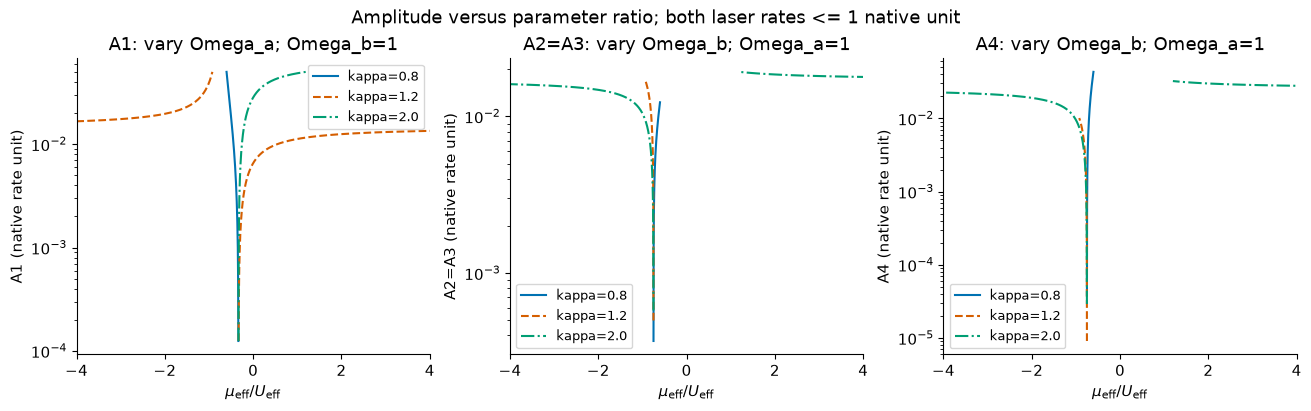

Amplitude-family sweep: 1200 samples per curve; separate branches at U_eff=0.


In [6]:
def signed_branches(interaction):
    cuts = np.flatnonzero(np.diff(np.sign(interaction)) != 0) + 1
    return [b for b in np.split(np.arange(len(interaction)), cuts) if len(b) > 1]

channels = [(0, 'A1'), (1, 'A2=A3'), (3, 'A4')]
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
    for ax, (channel, label) in zip(axes, channels):
        if channel == 0:
            omega_a = np.geomspace(0.05, 1.0, 1200)
            omega_b = np.ones_like(omega_a)
            sweep_label = 'vary Omega_a; Omega_b=1'
        else:
            omega_b = np.geomspace(0.03, 1.0, 1200)
            omega_a = np.ones_like(omega_b)
            sweep_label = 'vary Omega_b; Omega_a=1'
        for kappa, colour, style in zip(kappas, colours, styles):
            values = parameter_curves(kappa, (omega_b/omega_a)**2)
            for j, branch in enumerate(signed_branches(values['U'])):
                ax.plot(values['mu_over_U'][branch],
                        (omega_a**2*values['amplitudes'][channel])[branch],
                        color=colour, linestyle=style,
                        label=f'kappa={kappa}' if j == 0 else None)
        ax.set_yscale('log')
        ax.set(xlabel=r'$\mu_{\rm eff}/U_{\rm eff}$',
               ylabel=f'{label} (native rate unit)', xlim=(-4, 4),
               title=f'{label}: {sweep_label}')
        ax.legend(fontsize=9)
    fig.suptitle('Amplitude versus parameter ratio; both laser rates <= 1 native unit')
    show_figure(fig, '04_amplitudes_vs_mu_over_U')
print('Amplitude-family sweep: 1200 samples per curve; separate branches at U_eff=0.')

The second family fixes $\Omega_a=1$ and varies $r$; its vertical axis is
the bare $\mu_{\rm eff}$, and its horizontal axes are $A_i/U_{\rm eff}$.
The symmetric-log horizontal scale preserves both signs and a linear interval
near zero. A negative horizontal value means $U_{\rm eff}<0$ when $A_i>0$.
The bounded interval $10^{-3}\leq r\leq1$ keeps $\Omega_b\leq1$.
Each curve is split at a sign change of $U_{\rm eff}$ so the plot does not
draw a segment across an undefined ratio.

**Figure descriptions:** the preceding three panels show the three distinct
amplitude magnitudes along their labelled laser sweeps. The following three
panels show the source chemical-potential convention against normalized
amplitudes at fixed $\Omega_a$. Colour and line style identify $\kappa$;
equal-magnitude channels 2 and 3 share one panel. All vertical axes retain
the declared native rate unit.

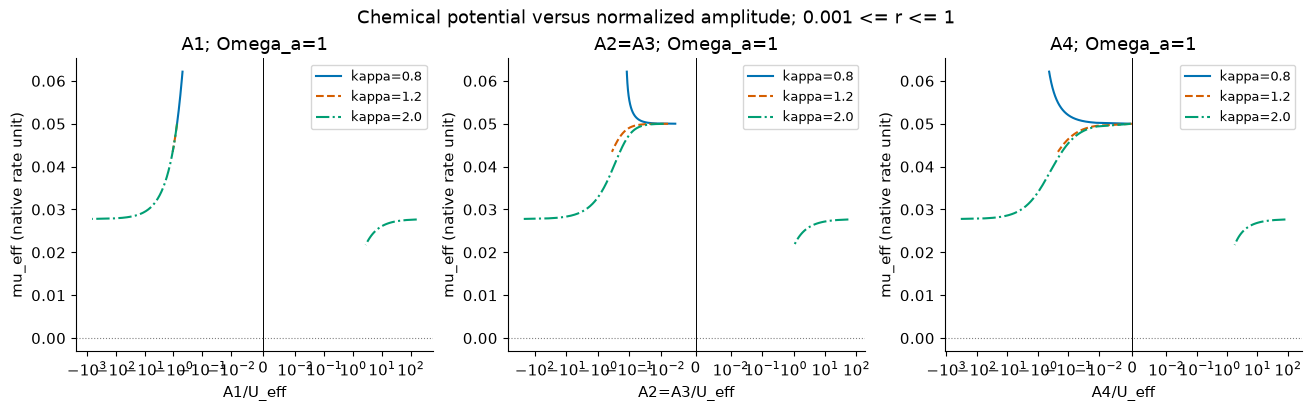

Chemical-potential-family sweep: bounded Omega_a=1 and Omega_b<=1.


In [7]:
bounded_r = np.geomspace(1e-3, 1.0, 1200)
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
    for ax, (channel, label) in zip(axes, channels):
        for kappa, colour, style in zip(kappas, colours, styles):
            values = parameter_curves(kappa, bounded_r)
            for j, branch in enumerate(signed_branches(values['U'])):
                ax.plot(values['amplitudes_over_U'][channel, branch], values['mu'][branch],
                        color=colour, linestyle=style,
                        label=f'kappa={kappa}' if j == 0 else None)
        ax.set_xscale('symlog', linthresh=1e-2)
        ax.axvline(0, color='black', linewidth=0.7)
        ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
        ax.set(xlabel=f'{label}/U_eff', ylabel='mu_eff (native rate unit)',
               title=f'{label}; Omega_a=1')
        ax.legend(fontsize=9)
    fig.suptitle('Chemical potential versus normalized amplitude; 0.001 <= r <= 1')
    show_figure(fig, '04_mu_vs_amplitude_over_U')
print('Chemical-potential-family sweep: bounded Omega_a=1 and Omega_b<=1.')

## Sources and limits of this notebook

- Aditya Banerjee, *Linear Anyon Model with Rydberg Atoms*, Universitat de
  Barcelona, 2026: [institutional record](https://hdl.handle.net/2445/231684).
  See the relevant sections and equations identified above.
- [Archived thesis and code deposit](https://doi.org/10.5281/zenodo.23443035).
- Original scripts in [`scripts/`](../scripts/) at source commit
  `22959963191fcbc4d283ec4b272b506ad6dd979b`; this notebook is a new explanatory
  implementation. The original script and data bytes are preserved.
- [SciPy `eigsh` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.eigsh.html)
  for the sparse eigenvalue solver. For complex Hermitian input, SciPy uses
  its complex eigensolver internally; residual checks remain necessary.

These finite-size calculations do not independently validate the microscopic
derivation, establish an experimental realization, or prove a thermodynamic
phase transition. No new empirical evidence is introduced.